In [1]:
## This notebook plots elastic scattering cross sections from NIST database and from Elsepa code

In [2]:
import pandas as pd
import numpy as np
import pylab as plt
%matplotlib inline

In [3]:
datEl=pd.read_csv("./Data/Elastic/Elsepa_elastic_DCS_18keV_H_He_Li_Kr.csv",skiprows=7,names=['Th','mu','H','He','Li','Kr','Hb','Heb','Lib','Krb','Hc','Hec','Lic','Krc'])

datH=pd.read_csv("./Data/Elastic/DCS_H_18000.csv",skiprows=10,names=['Th','XS'])
datHe=pd.read_csv("./Data/Elastic/DCS_He_18000.csv",skiprows=10,names=['Th','XS'])
datLi=pd.read_csv("./Data/Elastic/DCS_Li_18000.csv",skiprows=10,names=['Th','XS'])
datKr=pd.read_csv("./Data/Elastic/DCS_Kr_18000.csv",skiprows=10,names=['Th','XS'])

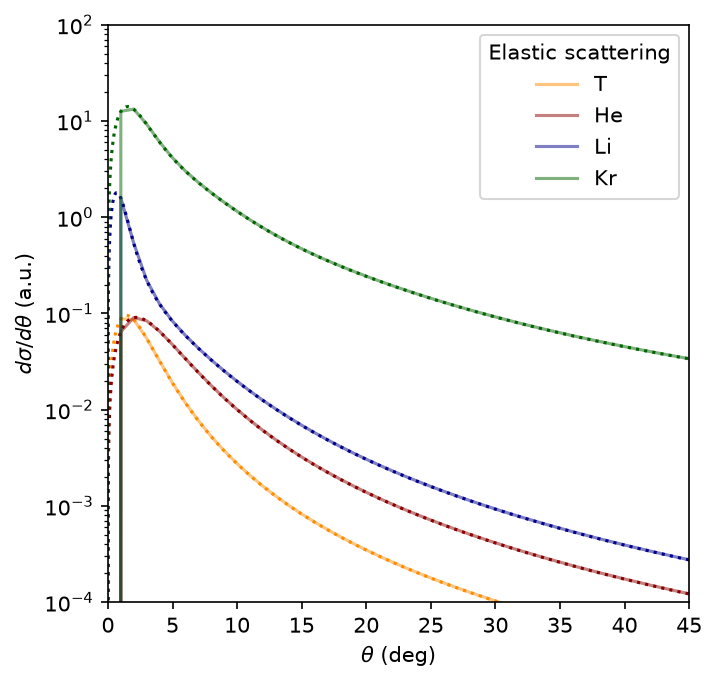

In [4]:
plt.figure(figsize=(5,5),dpi=150)
plt.plot(datH.Th,datH.XS,label='T',color='DarkOrange',alpha=0.5)
plt.plot(datEl.Th,2*np.pi*np.sin(datEl.Th*np.pi/180)*datEl.H/(5.3e-11**2*1e2**2),':',color='DarkOrange')

plt.plot(datHe.Th,datHe.XS,label='He',color='DarkRed',alpha=0.5)
plt.plot(datEl.Th,2*np.pi*np.sin(datEl.Th*np.pi/180)*datEl.He/(5.3e-11**2*1e2**2),':',color='DarkRed')

plt.plot(datLi.Th,datLi.XS,label='Li',color='DarkBlue',alpha=0.5)
plt.plot(datEl.Th,2*np.pi*np.sin(datEl.Th*np.pi/180)*datEl.Li/(5.3e-11**2*1e2**2),':',color='DarkBlue')

plt.plot(datKr.Th,datKr.XS,label='Kr',color='DarkGreen',alpha=0.5)
plt.plot(datEl.Th,2*np.pi*np.sin(datEl.Th*np.pi/180)/(5.3e-11**2*1e2**2)*datEl.Kr,':',color='DarkGreen')

plt.semilogy()
plt.ylim(1e-4,100)
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel(r"$d\sigma/ d\theta$ (a.u.)")
plt.legend(loc='upper right',title='Elastic scattering')
plt.xlim(0,45)
plt.savefig("Plots/NIST_Elastic.png",dpi=150)

In [10]:
datmol=pd.read_csv("./Data/Elastic/Elsepa_molecular_elastic_DCS_18keV_H2_N2_CO_O2.csv",skiprows=13)

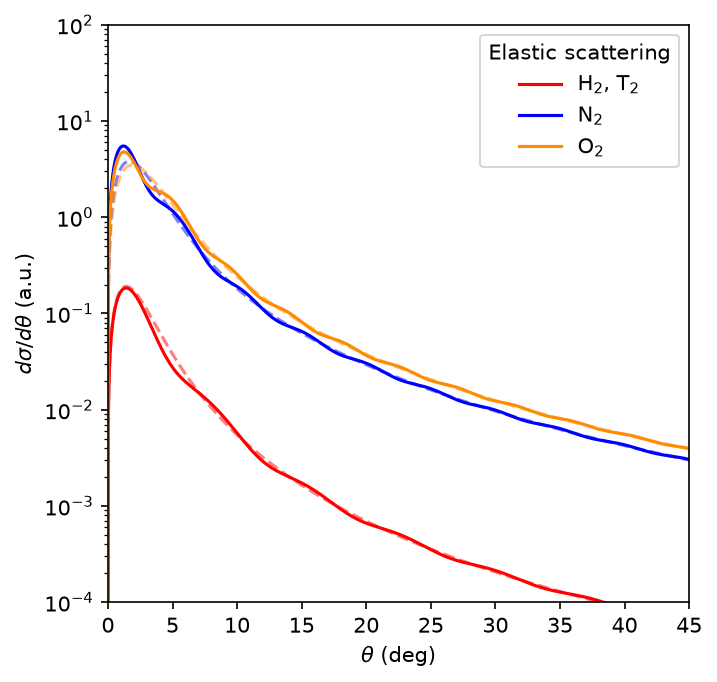

In [14]:
plt.figure(figsize=(5,5),dpi=150)
plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.H2_DCS_bonding_corrected,label=r'H$_2$, T$_2$',color='red')

plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.H2_IAM_incoherent_sum_of_atoms,'--',color='red',alpha=0.5)


plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.N2_DCS_bonding_corrected,label=r'N$_2$',color='blue')

plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.N2_IAM_incoherent_sum_of_atoms,'--',color='blue',alpha=0.5)


plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.O2_DCS_bonding_corrected,label=r'O$_2$',color='DarkOrange')

plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.O2_IAM_incoherent_sum_of_atoms,'--',color='DarkOrange',alpha=0.5)

#plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.CO_DCS_bonding_corrected,label=r'CO',color='dimgrey')

#plt.plot(datmol.theta_deg,2*np.pi*np.sin(datmol.theta_deg*np.pi/180)/(5.3e-11**2*1e2**2)*datmol.CO_IAM_incoherent_sum_of_atoms,'--',color='dimgrey',alpha=0.5)

plt.semilogy()
plt.ylim(1e-4,100)
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel(r"$d\sigma/ d\theta$ (a.u.)")
plt.legend(loc='upper right',title='Elastic scattering')
plt.xlim(0,45)
plt.savefig("Plots/Molecules_Elastic.png",dpi=150)

In [88]:
dat_Edep_a=pd.read_csv("./Data/Elastic/atoms_sigma_vs_energy_1-20keV.csv",skiprows=3)
dat_Edep_m=pd.read_csv("./Data/Elastic/molecules_sigma_vs_energy_1-20keV.csv",skiprows=6)


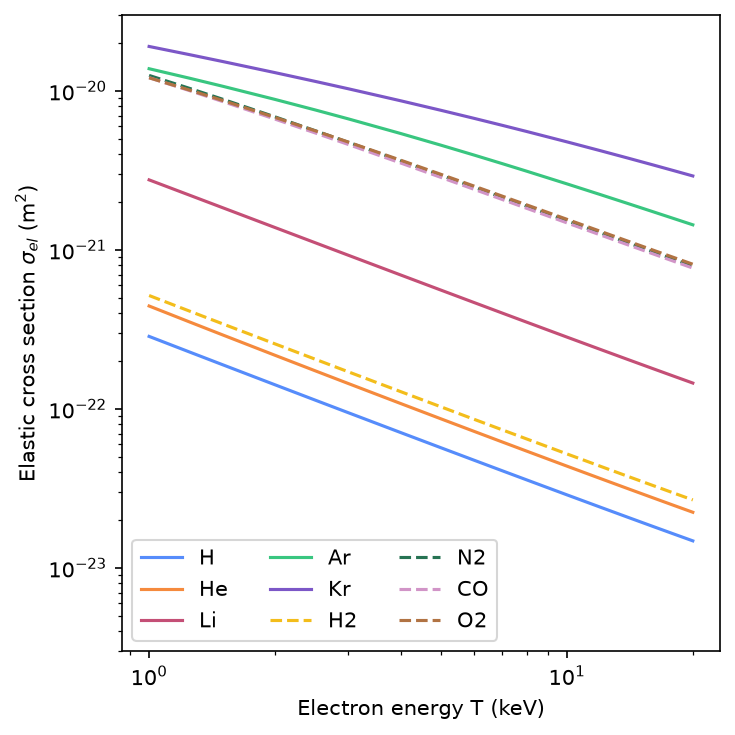

In [91]:


plt.figure(figsize=(5,5),dpi=150)
for c in dat_Edep_a.columns:
    if("_el" in c)  and (not ("Abs") in c):
        label=c.split("_")[0]
        plt.plot(dat_Edep_a.E_keV,dat_Edep_a[c]*1e-4,label=label)

for c in dat_Edep_m.columns:
    if("el_corrected" in c)  and (not ("Abs") in c):
        label=c.split("_")[0]
        plt.plot(dat_Edep_m.E_keV,dat_Edep_m[c]*1e-4,'--',label=label)

plt.loglog()
plt.legend(ncol=3)
plt.ylim(3e-24,3e-20)
plt.xlabel("Electron energy T (keV)")
plt.ylabel(r"Elastic cross section $\sigma_{el}$ (m$^2$)")
plt.tight_layout()
plt.savefig("Plots/Elastic_EnergyDep.png",dpi=150,bbox_inches='tight')
plt.show()


In [54]:
filename="./Data/Elastic/AngleTables/Kr_DCS_1-20keV.csv"
f=open(filename,'r')
lines=f.readlines()
f.close()
ci=0
for line in lines:
    if("theta_deg" in line):
        break
    ci=ci+1
dat_Kr_angle=pd.read_csv("./Data/Elastic/AngleTables/Kr_DCS_1-20keV.csv",skiprows=ci)

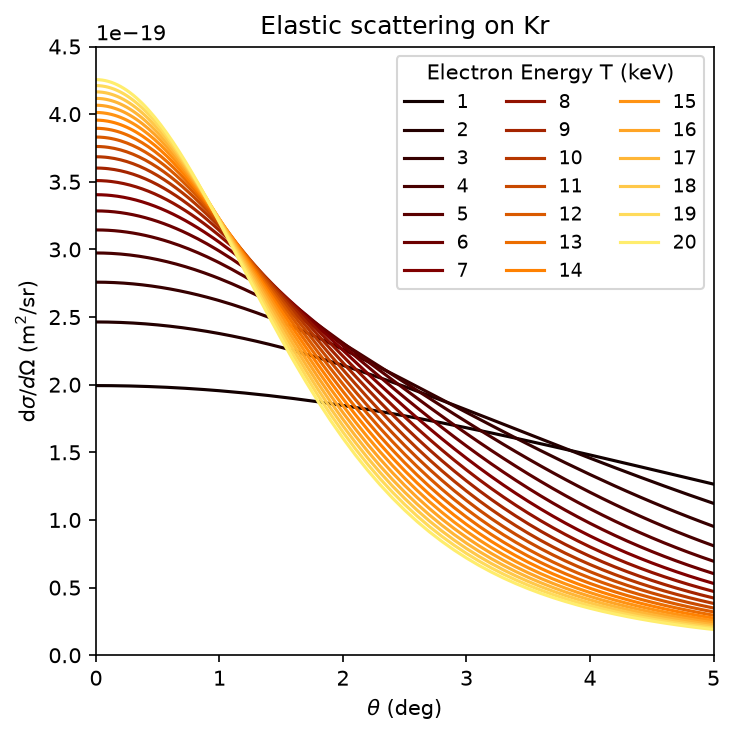

In [93]:
plt.figure(figsize=(5,5),dpi=150)
colormap=plt.get_cmap("afmhot")
for c in dat_Kr_angle.columns:
    if "DCS" in c:
        if not("." in c):
            label=c.split("_")[1][0:-3]
            plt.plot(dat_Kr_angle.theta_deg,dat_Kr_angle[c]*1e-4,label=label,color=colormap((int(label))/28))
plt.xlim(0,5)
plt.ylabel(r"d$\sigma/d\Omega$ (m$^2$/sr)")
plt.xlabel(r"$\theta$ (deg)")
plt.legend(loc='upper right',ncol=3,title='Electron Energy T (keV)',fontsize=9)
plt.title("Elastic scattering on Kr")
plt.ylim(0,4.5e-19)
plt.tight_layout()
plt.savefig("Plots/Kr_Angular.png",dpi=150,bbox_inches='tight')

